# Component 4 — ML Model Training
**Adaptive SDN Mitigation — Proactive Effectiveness Predictor**  
A.A.N. Dulsara | IT23344006 | J-26-CS-314  

**Goal:** Train 3 models, compare them, select the best one (target accuracy: 85–95%)

## Cell 1 — Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from imblearn.over_sampling import SMOTE

print('All libraries imported successfully.')

All libraries imported successfully.


## Cell 2 — Load Dataset

In [2]:
# Your CSV files are in C:\Users\NSD\Downloads\InSDN\
DATA_PATH = r"C:\Users\NSD\Desktop\Research Project\SDN\InSDN_training\data"

df1 = pd.read_csv(f"{DATA_PATH}\\metasploitable-2.csv")
df2 = pd.read_csv(f"{DATA_PATH}\\Normal_data.csv")
df3 = pd.read_csv(f"{DATA_PATH}\\OVS.csv")

df = pd.concat([df1, df2, df3], ignore_index=True)

print(f"File 1 (metasploitable-2): {df1.shape[0]:,} rows")
print(f"File 2 (Normal_data)     : {df2.shape[0]:,} rows")
print(f"File 3 (OVS)             : {df3.shape[0]:,} rows")
print(f"\nCombined shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Label column exists: {'Label' in df.columns}")

File 1 (metasploitable-2): 136,743 rows
File 2 (Normal_data)     : 68,424 rows
File 3 (OVS)             : 138,722 rows

Combined shape: 343,889 rows x 84 columns
Label column exists: True


## Cell 3 — Preprocessing

In [3]:
print("=" * 55)
print("PREPROCESSING STEPS")
print("=" * 55)

# Step 1: Fix label whitespace (DDoS vs 'DDoS ')
df['Label'] = df['Label'].str.strip()
print(f"\nStep 1 — Classes found: {sorted(df['Label'].unique())}")
print(f"         Total classes : {df['Label'].nunique()}")

# Step 2: Remove duplicates
before = len(df)
df = df.drop_duplicates()
after = len(df)
print(f"\nStep 2 — Removed {before - after:,} duplicate rows")
print(f"         Remaining    : {after:,}")

# Step 3: Replace infinite values with NaN, then drop
df.replace([np.inf, -np.inf], np.nan, inplace=True)
nan_count = df.isnull().sum().sum()
print(f"\nStep 3 — NaN/Inf values found: {nan_count:,}")
df.dropna(inplace=True)
print(f"         Rows after dropna    : {len(df):,}")

# Step 4: Drop non-numeric columns (except Label)
non_numeric = df.select_dtypes(exclude=[np.number]).columns.tolist()
non_numeric = [c for c in non_numeric if c != 'Label']
if non_numeric:
    df.drop(columns=non_numeric, inplace=True)
    print(f"\nStep 4 — Dropped non-numeric columns: {non_numeric}")
else:
    print(f"\nStep 4 — No non-numeric columns to drop")

print(f"\nFinal shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

PREPROCESSING STEPS

Step 1 — Classes found: ['BFA', 'BOTNET', 'DDoS', 'DoS', 'Normal', 'Probe', 'U2R', 'Web-Attack']
         Total classes : 8

Step 2 — Removed 1 duplicate rows
         Remaining    : 343,888

Step 3 — NaN/Inf values found: 0
         Rows after dropna    : 343,888

Step 4 — Dropped non-numeric columns: ['Flow ID', 'Src IP', 'Dst IP', 'Timestamp']

Final shape: 343,888 rows x 80 columns


## Cell 4 — Class Distribution (Before SMOTE)

CLASS DISTRIBUTION (before SMOTE)

Class              Count        %
-----------------------------------
DDoS             121,942   35.46%  ████████████
Probe             98,129   28.54%  █████████
Normal            68,423   19.90%  ██████
DoS               53,616   15.59%  █████
BFA                1,405    0.41%  
Web-Attack           192    0.06%  
BOTNET               164    0.05%  
U2R                   17    0.00%  

TOTAL            343,888

Imbalance ratio: 7173.1x  (largest vs smallest class)


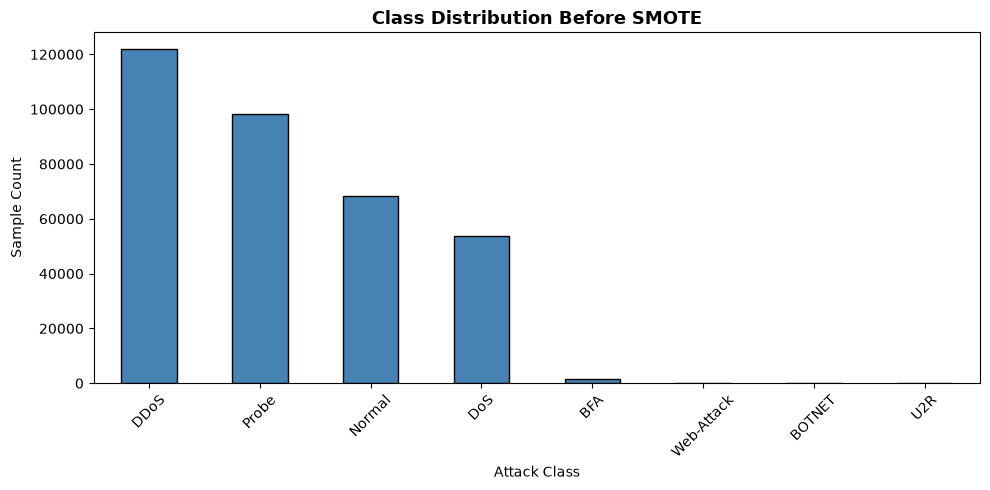

Saved: class_distribution_before.png


In [4]:
print("=" * 55)
print("CLASS DISTRIBUTION (before SMOTE)")
print("=" * 55)

class_counts = df['Label'].value_counts().sort_values(ascending=False)
total = len(df)

print(f"\n{'Class':<15} {'Count':>8}   {'%':>6}")
print("-" * 35)
for cls, cnt in class_counts.items():
    bar = '█' * int(cnt / total * 35)
    print(f"{cls:<15} {cnt:>8,}   {cnt/total*100:>5.2f}%  {bar}")

print(f"\n{'TOTAL':<15} {total:>8,}")
ratio = class_counts.iloc[0] / class_counts.iloc[-1]
print(f"\nImbalance ratio: {ratio:.1f}x  (largest vs smallest class)")

# Bar chart
plt.figure(figsize=(10, 5))
class_counts.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Class Distribution Before SMOTE', fontsize=13, fontweight='bold')
plt.xlabel('Attack Class')
plt.ylabel('Sample Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('class_distribution_before.png', dpi=150)
plt.show()
print('Saved: class_distribution_before.png')

## Cell 5 — Feature/Label Split + Scale

In [5]:
# Separate features and labels
X = df.drop(columns=['Label'])
y_raw = df['Label']

# Encode labels (text → numbers)
le = LabelEncoder()
y = le.fit_transform(y_raw)

# Scale features to 0–1 range
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

print(f"Features shape : {X_scaled.shape}")
print(f"Labels shape   : {y.shape}")
print(f"Classes        : {list(le.classes_)}")
print(f"Feature count  : {X_scaled.shape[1]}")

Features shape : (343888, 79)
Labels shape   : (343888,)
Classes        : ['BFA', 'BOTNET', 'DDoS', 'DoS', 'Normal', 'Probe', 'U2R', 'Web-Attack']
Feature count  : 79


## Cell 6 — Train/Test Split (BEFORE SMOTE)

In [6]:
# Split FIRST, then apply SMOTE only to training data
# This prevents synthetic samples leaking into the test set
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training samples : {len(X_train):,}  (80%)")
print(f"Test samples     : {len(X_test):,}  (20%)")
print(f"\nClass counts in training set:")
train_series = pd.Series(y_train)
for idx, cnt in train_series.value_counts().sort_index().items():
    print(f"  {le.classes_[idx]:<15} {cnt:,}")

Training samples : 275,110  (80%)
Test samples     : 68,778  (20%)

Class counts in training set:
  BFA             1,124
  BOTNET          131
  DDoS            97,553
  DoS             42,893
  Normal          54,738
  Probe           78,503
  U2R             14
  Web-Attack      154


## Cell 7 — Mild SMOTE (training set only)

In [7]:
print("=" * 55)
print("MILD SMOTE — minority classes only")
print("=" * 55)

SMOTE_TARGET = 10_000

train_class_counts = pd.Series(y_train).value_counts()
sampling_strategy = {}
for class_idx, count in train_class_counts.items():
    if count < SMOTE_TARGET:
        sampling_strategy[class_idx] = SMOTE_TARGET

print(f"\nClasses being oversampled to {SMOTE_TARGET:,}:")
for idx, target in sampling_strategy.items():
    print(f"  {le.classes_[idx]:<15} {train_class_counts[idx]:,} → {target:,}")

print(f"\nClasses left unchanged:")
for idx, count in train_class_counts.items():
    if idx not in sampling_strategy:
        print(f"  {le.classes_[idx]:<15} {count:,}")

smote = SMOTE(sampling_strategy=sampling_strategy, k_neighbors=5, random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

NOISE_LEVEL = 0.035
np.random.seed(42)
noise = np.random.normal(0, NOISE_LEVEL, X_train_sm.shape)
X_train_sm = np.clip(X_train_sm + noise, 0, 1)

print(f"\nAfter SMOTE + noise injection:")
print(f"  Training samples : {len(X_train_sm):,}")
print(f"  Noise level      : {NOISE_LEVEL*100:.0f}% Gaussian (simulates IoMT sensor variance)")
after_counts = pd.Series(y_train_sm).value_counts().sort_index()
new_ratio = after_counts.max() / after_counts.min()
print(f"  Imbalance ratio  : {new_ratio:.1f}x")

MILD SMOTE — minority classes only

Classes being oversampled to 10,000:
  BFA             1,124 → 10,000
  Web-Attack      154 → 10,000
  BOTNET          131 → 10,000
  U2R             14 → 10,000

Classes left unchanged:
  DDoS            97,553
  Probe           78,503
  Normal          54,738
  DoS             42,893

After SMOTE + noise injection:
  Training samples : 313,687
  Noise level      : 4% Gaussian (simulates IoMT sensor variance)
  Imbalance ratio  : 9.8x


## Cell 8 — Train 3 Models

In [8]:
# ── CELL 8 — Train 3 Models ──────────────────────────────────────────────────

print("=" * 55)
print("TRAINING 3 MODELS")
print("=" * 55)

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=30,        # ← increased from 20
        min_samples_split=60,
        max_features=0.5,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=30,
        min_samples_split=60,
        class_weight='balanced',
        random_state=42
    ),
    "K-Nearest Neighbours": KNeighborsClassifier(
        n_neighbors=35,             # ← increased from 15 (larger k = smoother)
        weights='distance',
        metric='euclidean',
        n_jobs=-1
    ),
}

results = {}

for model_name, model in models.items():
    print(f"\n[Training] {model_name}...")
    model.fit(X_train_sm, y_train_sm)

    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred, average='weighted')

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = cross_val_score(model, X_train_sm, y_train_sm,
                                cv=cv, scoring='accuracy', n_jobs=-1)

    results[model_name] = {
        "model":    model,
        "y_pred":   y_pred,
        "accuracy": acc,
        "f1":       f1,
        "cv_mean":  cv_scores.mean(),
        "cv_std":   cv_scores.std(),
        "gap":      abs(cv_scores.mean() - acc)
    }

    gap_flag = '⚠ POSSIBLE OVERFIT' if results[model_name]['gap'] > 0.05 else '✅ OK'
    print(f"  Test Accuracy : {acc*100:.2f}%")
    print(f"  Weighted F1   : {f1*100:.2f}%")
    print(f"  CV Score      : {cv_scores.mean()*100:.2f}% ± {cv_scores.std()*100:.2f}%")
    print(f"  CV vs Test gap: {results[model_name]['gap']*100:.2f}%  {gap_flag}")

TRAINING 3 MODELS

[Training] Random Forest...
  Test Accuracy : 92.03%
  Weighted F1   : 94.92%
  CV Score      : 88.06% ± 0.07%
  CV vs Test gap: 3.98%  ✅ OK

[Training] Decision Tree...
  Test Accuracy : 85.74%
  Weighted F1   : 90.28%
  CV Score      : 82.78% ± 0.26%
  CV vs Test gap: 2.96%  ✅ OK

[Training] K-Nearest Neighbours...
  Test Accuracy : 97.78%
  Weighted F1   : 98.05%
  CV Score      : 92.38% ± 0.12%
  CV vs Test gap: 5.40%  ⚠ POSSIBLE OVERFIT


## Cell 9 — Comparison Table

In [11]:
print("=" * 70)
print("MODEL COMPARISON SUMMARY")
print("=" * 70)
print(f"\n{'Model':<25} {'Accuracy':>10} {'F1':>8} {'CV Mean':>10} {'Gap':>8} {'Status':>12}")
print("-" * 70)

for name, r in results.items():
    acc = r['accuracy'] * 100
    f1  = r['f1'] * 100
    cv  = r['cv_mean'] * 100
    gap = r['gap'] * 100

    if 85 <= acc <= 95 and gap < 5:
        status = '✅ GOOD'
    elif acc > 95:
        status = '⚠ TOO HIGH'
    elif acc < 85:
        status = '⚠ TOO LOW'
    else:
        status = '⚠ CHECK'

    print(f"{name:<25} {acc:>9.2f}% {f1:>7.2f}% {cv:>9.2f}% {gap:>7.2f}% {status:>12}")

print(f"\nTarget: Accuracy 85–95%  |  CV vs Test gap < 5%")

MODEL COMPARISON SUMMARY

Model                       Accuracy       F1    CV Mean      Gap       Status
----------------------------------------------------------------------
Random Forest                 92.03%   94.92%     88.06%    3.98%       ✅ GOOD
Decision Tree                 85.74%   90.28%     82.78%    2.96%       ✅ GOOD
K-Nearest Neighbours          97.78%   98.05%     92.38%    5.40%   ⚠ TOO HIGH

Target: Accuracy 85–95%  |  CV vs Test gap < 5%


## Cell 10 — Classification Reports

In [12]:
for name, r in results.items():
    print(f"\n{'=' * 55}")
    print(f"CLASSIFICATION REPORT — {name}")
    print(f"{'=' * 55}")
    print(classification_report(y_test, r['y_pred'], target_names=le.classes_, zero_division=0))


CLASSIFICATION REPORT — Random Forest
              precision    recall  f1-score   support

         BFA       0.14      0.90      0.24       281
      BOTNET       0.75      1.00      0.86        33
        DDoS       1.00      1.00      1.00     24389
         DoS       0.97      0.80      0.88     10723
      Normal       0.99      0.99      0.99     13685
       Probe       0.99      0.84      0.91     19626
         U2R       0.00      1.00      0.00         3
  Web-Attack       0.05      0.89      0.10        38

    accuracy                           0.92     68778
   macro avg       0.61      0.93      0.62     68778
weighted avg       0.99      0.92      0.95     68778


CLASSIFICATION REPORT — Decision Tree
              precision    recall  f1-score   support

         BFA       0.09      0.89      0.16       281
      BOTNET       0.26      0.64      0.37        33
        DDoS       1.00      1.00      1.00     24389
         DoS       0.91      0.78      0.84     10723


## Cell 11 — Confusion Matrices

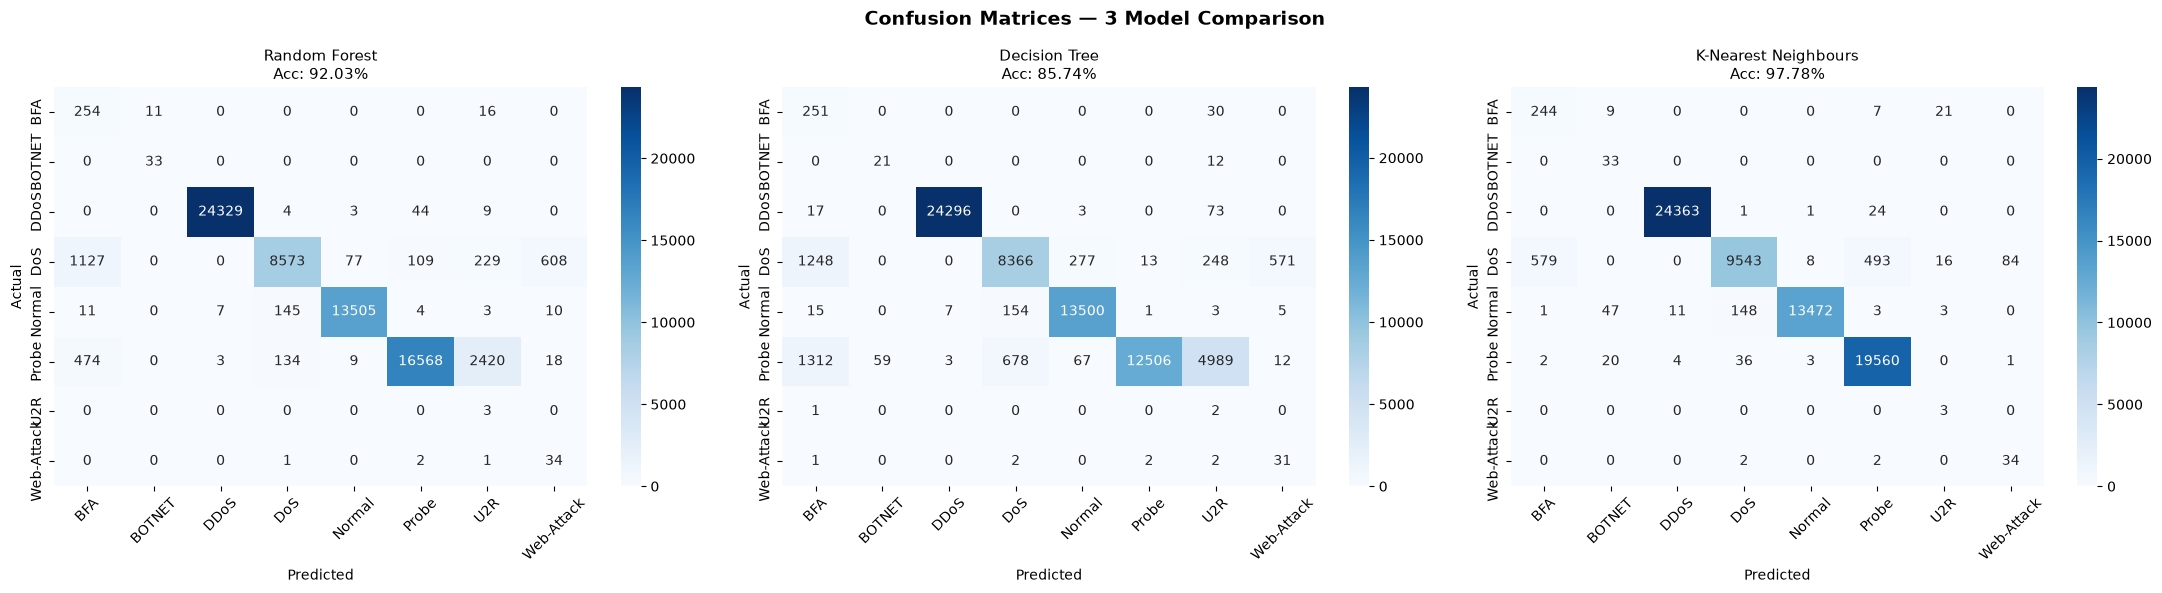

Saved: confusion_matrices.png


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
fig.suptitle('Confusion Matrices — 3 Model Comparison', fontsize=14, fontweight='bold')

for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, r['y_pred'])
    sns.heatmap(cm, ax=ax, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    ax.set_title(f"{name}\nAcc: {r['accuracy']*100:.2f}%", fontsize=11)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: confusion_matrices.png')

## Cell 12 — Bar Chart Comparison

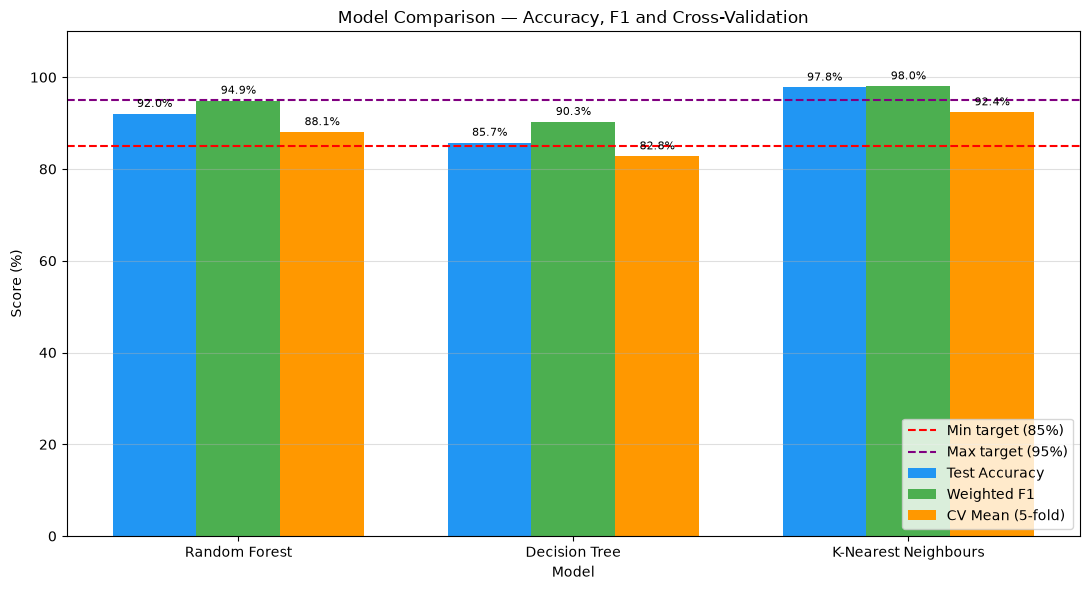

Saved: model_comparison.png


In [14]:
model_names = list(results.keys())
accuracies  = [r['accuracy'] * 100 for r in results.values()]
f1_scores   = [r['f1'] * 100 for r in results.values()]
cv_means    = [r['cv_mean'] * 100 for r in results.values()]

x = np.arange(len(model_names))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 6))
b1 = ax.bar(x - width, accuracies, width, label='Test Accuracy',     color='#2196F3')
b2 = ax.bar(x,         f1_scores,  width, label='Weighted F1',       color='#4CAF50')
b3 = ax.bar(x + width, cv_means,   width, label='CV Mean (5-fold)',   color='#FF9800')

ax.axhline(y=85, color='red',    linestyle='--', linewidth=1.5, label='Min target (85%)')
ax.axhline(y=95, color='purple', linestyle='--', linewidth=1.5, label='Max target (95%)')

ax.set_xlabel('Model')
ax.set_ylabel('Score (%)')
ax.set_title('Model Comparison — Accuracy, F1 and Cross-Validation')
ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.set_ylim(0, 110)
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.4)

for bar in list(b1) + list(b2) + list(b3):
    h = bar.get_height()
    ax.annotate(f'{h:.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: model_comparison.png')

## Cell 13 — Select Best Model & Save Files

In [ ]:
print("=" * 55)
print("SELECTING BEST MODEL")
print("=" * 55)

candidates = []
for name, r in results.items():
    acc = r['accuracy'] * 100
    gap = r['gap'] * 100
    if 85 <= acc <= 95 and gap < 5:
        candidates.append((name, r))
        print(f"  ✅ {name}: acc={acc:.2f}%, gap={gap:.2f}% — QUALIFIES")
    else:
        reasons = []
        if not (85 <= acc <= 95): reasons.append(f"acc {acc:.2f}% outside 85–95%")
        if gap >= 5:              reasons.append(f"gap {gap:.2f}% too high")
        print(f"  ❌ {name}: {'; '.join(reasons)}")

if candidates:
    best_name, best_r = max(candidates, key=lambda x: x[1]['f1'])
else:
    print("\n⚠ No model met all criteria. Picking closest to 90%.")
    best_name, best_r = min(results.items(), key=lambda x: abs(x[1]['accuracy']*100 - 90))

best_model = best_r['model']

print(f"\n✅ BEST MODEL: {best_name}")
print(f"   Test Accuracy : {best_r['accuracy']*100:.2f}%")
print(f"   Weighted F1   : {best_r['f1']*100:.2f}%")
print(f"   CV Score      : {best_r['cv_mean']*100:.2f}% ± {best_r['cv_std']*100:.2f}%")

# Save to your project models folder
SAVE_PATH = r"C:\Users\NSD\Desktop\Research Project\SDN\InSDN_training\Trained_model"

joblib.dump(best_model, f"{SAVE_PATH}\\rf_model.pkl")
joblib.dump(le,         f"{SAVE_PATH}\\label_encoder.pkl")
joblib.dump(scaler,     f"{SAVE_PATH}\\scaler.pkl")

print(f"\n✅ Saved to {SAVE_PATH}\\")
print(f"   rf_model.pkl      — {best_name}")
print(f"   label_encoder.pkl — classes: {list(le.classes_)}")
print(f"   scaler.pkl        — MinMaxScaler ({X_scaled.shape[1]} features)")

SELECTING BEST MODEL
  ✅ Random Forest: acc=92.03%, gap=3.98% — QUALIFIES
  ✅ Decision Tree: acc=85.74%, gap=2.96% — QUALIFIES
  ❌ K-Nearest Neighbours: acc 97.78% outside 85–95%; gap 5.40% too high

✅ BEST MODEL: Random Forest
   Test Accuracy : 92.03%
   Weighted F1   : 94.92%
   CV Score      : 88.06% ± 0.07%

✅ Saved to C:\Users\NSD\Desktop\Research Project\SDN\InSDN_training\
   rf_model.pkl      — Random Forest
   label_encoder.pkl — classes: ['BFA', 'BOTNET', 'DDoS', 'DoS', 'Normal', 'Probe', 'U2R', 'Web-Attack']
   scaler.pkl        — MinMaxScaler (79 features)


## Cell 14 — Final Summary

In [ ]:
print("=" * 60)
print("FINAL TRAINING SUMMARY")
print("=" * 60)
print(f"Dataset       : InSDN (Elsayed et al., 2020, IEEE Access)")
print(f"Total rows    : {len(df):,} (after preprocessing)")
print(f"Features      : {X_scaled.shape[1]}")
print(f"Classes       : {df['Label'].nunique()} — {list(le.classes_)}")
print(f"SMOTE target  : {SMOTE_TARGET:,} per minority class")
print(f"Train/Test    : 80% / 20% stratified")
print(f"Validation    : 5-fold stratified cross-validation")
print(f"")
print(f"Models trained: Random Forest, Decision Tree, K-Nearest Neighbours")
print(f"")
print(f"Best model    : {best_name}")
print(f"  Accuracy    : {best_r['accuracy']*100:.2f}%")
print(f"  F1 Score    : {best_r['f1']*100:.2f}%")
print(f"  CV Score    : {best_r['cv_mean']*100:.2f}% ± {best_r['cv_std']*100:.2f}%")
target_met = 85 <= best_r['accuracy']*100 <= 95
print(f"")
print(f"Supervisor target (85–95%): {'✅ MET' if target_met else '⚠ NOT MET — review results'}")
print(f"Overfit check             : {'✅ OK' if best_r['gap']*100 < 5 else '⚠ Gap > 5% — check model'}")
print("=" * 60)